# MiniProject 1: Comparing Two Inaugural Addresses
**Me:** ttb615  **Group:** 12

I picked two U.S. presidential inaugural addresses from different time periods of American history: George Washington's first inaugural (1789) and John F. Kennedy's inaugural (1961). They're both "inaugural addresses" by definition, but 172 years and a totally different media environment makes them very distinct. I wanted to see whether that gap actually shows up in the words and the writing itself, or whether the genre pulls both toward the same vocabulary and tone.

- Washington's First Inaugural Address (1789) — National Archives
- JFK's Inaugural Address (1961) — National Archives / Avalon Project

## Three things I want to know
1. **Top words:** what vocabulary does each president use the most?
2. **Signature words:** are there words one of them uses way more than the other, once we control for speech length?
3. **Writing style:** does the sentence structure/vocabulary richness reflect the shift from a written 18th-century address to a spoken 20th-century one?


## Set up
Loading tools I need and writing a list of words to ignore (*the, and, is*, and punctuation) so the interesting words stand out.

In [ ]:
import re, operator, math
from collections import Counter
import nltk
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

nltk.download('stopwords', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

# stop words 
stop_words = set(nltk.corpus.stopwords.words('english')) | {
    'ut', "'re", '.', ',', '--', "'s", '?', ')', '(', ':', "'",
    '"', '-', '}', '{', '&', '|', u'\u2014', '',
}

## Cleaning the text 
These came as plain text, so cleaning simple: lowercase everything, ignore punctuation, numbers, and the repetitive, uniteresting words. What's left is the vocabulary each president used.

In [ ]:
def clean_word(w):
    # remove punctuation
    wn = re.sub(r'[,"\.\'&\|:@>*;/=!\?\)\(\[\]]', '', w)
    # numbers
    return re.sub(r'^[0-9\.]*$', '', wn)

def get_wf(path):
    """Return (Counter of word frequencies, total regular-word count)."""
    with open(path, 'r', encoding='utf-8', errors='replace') as f:
        text = f.read()
    words = []
    for raw in text.split():
        w = clean_word(raw.lower())
        if w and w not in stop_words:
            words.append(w)
    return Counter(words), len(words)

## Reading in the two addresses
Loading each speech and printing how many content words (after cleaning) are left. 

In [3]:
ADDRESSES = {
    'Washington 1789': 'washington.txt',
    'JFK 1961':         'jfk.txt',
}

wf = {}
totals = {}
for name, path in ADDRESSES.items():
    wf[name], totals[name] = get_wf(path)
    print(f'{name:20s} content words: {totals[name]:>6d}')

Washington 1789      content words:    646
JFK 1961             content words:    693


### Top 15 most-used content words in each address
What each president leans on most once function words are stripped out.

In [4]:
for name in ADDRESSES:
    print(f'\n=== {name} ===')
    for w, c in wf[name].most_common(15):
        print(f'  {w:15s}{c}')


=== Washington 1789 ===
  every          9
  government     8
  public         6
  may            6
  present        5
  country        5
  one            4
  ought          4
  duty           4
  people         4
  united         4
  since          4
  fellow-citizens3
  could          3
  hand           3

=== JFK 1961 ===
  let            16
  us             12
  world          8
  sides          8
  new            7
  citizens       5
  power          5
  shall          5
  pledge         5
  free           5
  nations        5
  president      4
  fellow         4
  man            4
  first          4


## Bar charts
Even though the two speeches are close in length, I still compute how often a word shows up every 1000 words. That keeps the comparison fair and makes this reusable if I ever add a much longer or shorter speech later. This function draws two addresses side by side.

In [ ]:
def top_rates(name, n=15):
    tot = totals[name]
    items = [(w, 1000.0 * c / tot) for w, c in wf[name].most_common(n)]
    return items[::-1] 

def plot_two(a, b, title):
    fa, fb = top_rates(a), top_rates(b)
    f = plt.figure(figsize=(12, 6))
    f.suptitle(title, fontsize=16)
    ax1 = f.add_subplot(121)
    ax1.barh(range(len(fa)), [x[1] for x in fa], align='center')
    ax1.set_yticks(range(len(fa)))
    ax1.set_yticklabels([x[0] for x in fa])
    ax1.set_title(a); ax1.set_xlabel('per 1000 words')
    ax2 = f.add_subplot(122)
    ax2.barh(range(len(fb)), [x[1] for x in fb], align='center', color='tab:orange')
    ax2.set_yticks(range(len(fb)))
    ax2.set_yticklabels([x[0] for x in fb])
    ax2.set_title(b); ax2.set_xlabel('per 1000 words')
    plt.tight_layout()
    plt.show()

## Question 1: Top words side by side
Do Washington and JFK talk about the same things?

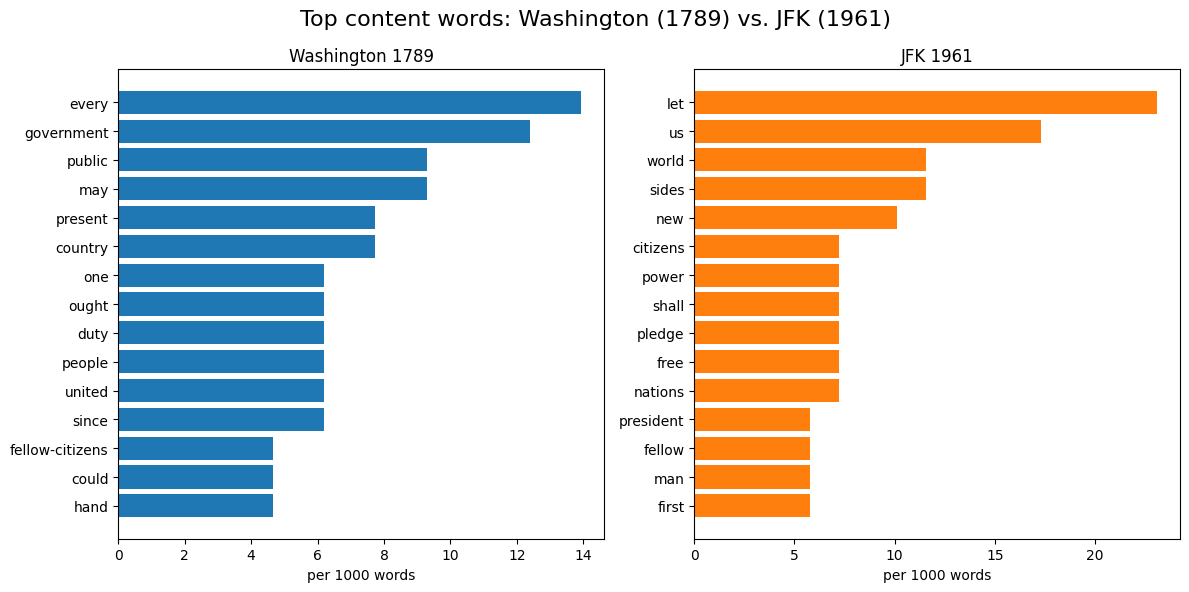

In [6]:
plot_two('Washington 1789', 'JFK 1961',
         'Top content words: Washington (1789) vs. JFK (1961)')

## Question 2: Signature words
Here I compare word rates directly and pull out the words each president favors way more than the other. I only count words that show up enough total times (more than 3 combined) so I'm not chasing one-off flukes in these relatively short speeches.

In [7]:
wash, jfk = wf['Washington 1789'], wf['JFK 1961']
wash_tot, jfk_tot = totals['Washington 1789'], totals['JFK 1961']

def rate(counter, tot):
    return {w: 1000.0 * c / tot for w, c in counter.items()}

wr, jr = rate(wash, wash_tot), rate(jfk, jfk_tot)
common = set(wr) | set(jr)
diff = sorted(
    ((w, wr.get(w, 0) - jr.get(w, 0)) for w in common
     if wash.get(w, 0) + jfk.get(w, 0) > 3),
    key=operator.itemgetter(1)
)

print('Words JFK favors over Washington (rate diff per 1000):')
for w, d in diff[:12]:
    print(f'  {w:15s}{-d:6.2f}')
print('\nWords WASHINGTON favors over JFK (rate diff per 1000):')
for w, d in diff[-12:][::-1]:
    print(f'  {w:15s}{d:6.2f}')

Words JFK favors over Washington (rate diff per 1000):
  let             23.09
  us              15.77
  sides           11.54
  world           10.00
  new              8.55
  pledge           7.22
  help             5.77
  fellow           5.77
  always           5.77
  cannot           5.77
  peace            5.77
  war              5.77

Words WASHINGTON favors over JFK (rate diff per 1000):
  government      12.38
  every           11.05
  public           9.29
  present          6.30
  duty             6.19
  ought            6.19
  may              4.96
  people           4.75
  since            4.75
  united           3.31
  must             3.20
  great            3.20


## Question 3: Writing style 
Word choice is one thing, but how each president builds a sentence might say more about the shift from a written address to a televised one.

Washington 1789      sentences:  23   avg sentence length:  61.9 words   avg word length: 4.93 chars   lexical diversity: 0.416
JFK 1961             sentences:  52   avg sentence length:  26.2 words   avg word length: 4.38 chars   lexical diversity: 0.387


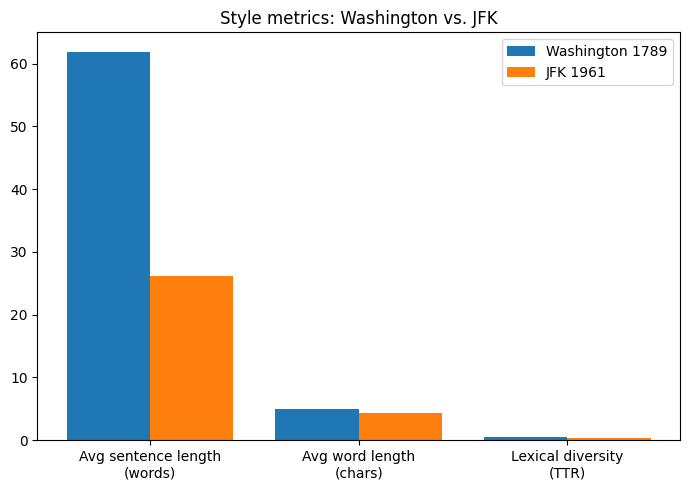

In [8]:
from nltk.tokenize import sent_tokenize, word_tokenize

def style_stats(path):
    text = open(path, encoding='utf-8').read()
    sentences = sent_tokenize(text)
    words = [w for w in word_tokenize(text) if w.isalpha()]
    ttr = len(set(w.lower() for w in words)) / len(words)
    avg_sent_len = len(words) / len(sentences)
    avg_word_len = sum(len(w) for w in words) / len(words)
    return len(sentences), avg_sent_len, avg_word_len, ttr

for name, path in ADDRESSES.items():
    n_sent, avg_sent, avg_word, ttr = style_stats(path)
    print(f'{name:20s} sentences: {n_sent:3d}   avg sentence length: {avg_sent:5.1f} words   '
          f'avg word length: {avg_word:4.2f} chars   lexical diversity: {ttr:.3f}')

labels = ['Avg sentence length\n(words)', 'Avg word length\n(chars)', 'Lexical diversity\n(TTR)']
wash_vals = list(style_stats('washington.txt'))[1:]
jfk_vals = list(style_stats('jfk.txt'))[1:]

x = np.arange(len(labels))
f, ax = plt.subplots(figsize=(7,5))
ax.bar(x - 0.2, wash_vals, width=0.4, label='Washington 1789')
ax.bar(x + 0.2, jfk_vals, width=0.4, label='JFK 1961', color='tab:orange')
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_title('Style metrics: Washington vs. JFK')
ax.legend()
plt.tight_layout()
plt.show()

## What I found

- **Q1 (top words):** Washington's most-used words are institutional and abstract (government, public, duty, country) while JFK's are imperative and audience-directed (let, us, world, pledge, free). They're both talking about "the nation," but Washington describes it from the outside (as an institution) and JFK addresses it directly (as a call to action).
- **Q2 (signature words):** Washington's signature words skew toward "government", "public", "duty", "country", and "one", the vocabulary of describing a new constitutional system. JFK's skew toward "let", "us", "sides", "world", "pledge", "new", the vocabulary of a Cold War speech meant to be quoted and remembered in short bursts.
- **Q3 (style):** Washington's sentences run roughly 60+ words on average. They're long, subordinate-clause-heavy 18th-century prose meant to be read. JFK's sentences average roughly half that. They're short, rhythmic, and built for a spoken/broadcast delivery. Lexical diversity is fairly close between the two, so it's really sentence construction, not vocabulary richness, that shows the change in style.

### Problems
- Even though both speeches are similar in raw length, I kept the rate-per-1000-words normalization instead of raw counts, since it's the more defensible approach if I extend this to speeches of very different lengths later.
- Some of Washington's words (e.g., contractions with the long dash "—") needed punctuation-stripping treatment. 
